# Task 4 · Email Spam Detection with Machine Learning

**Track:** Data Science

**Author:** Robin Kumar

**Objective:** Build a Natural Language Processing (NLP) classifier that separates spam messages from legitimate (ham) messages.

**Dataset:** SMS Spam Collection from the UCI Machine Learning Repository, saved in this repository as `sms_spam_collection.tsv`. It contains short text messages labelled as `spam` or `ham`. The same steps work for email text.

**Steps in this notebook**
1. Import libraries
2. Load the dataset and check the class distribution
3. Data cleaning
4. Text preprocessing
5. WordClouds (bonus)
6. Train / test split
7. Feature extraction with TF-IDF
8. Train the classifiers
9. Evaluate the classifiers
10. Why recall is important for spam detection
11. Best model
12. Conclusion

## 1. Import libraries

In [1]:
import string

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Download the list of English stopwords (needed only the first time)
nltk.download("stopwords", quiet=True)

sns.set_theme(style="whitegrid")
ham_color = "#2a78d6"     # blue for ham
spam_color = "#eb6834"    # orange for spam

## 2. Load the dataset and check the class distribution

The file has no header row and the two columns are separated by a tab: the label (`ham` or `spam`) and the message text.

In [2]:
# quoting=3 tells pandas not to treat quotation marks inside the messages as special characters
df = pd.read_csv("sms_spam_collection.tsv", sep="\t", header=None, names=["label", "message"], quoting=3)

print("Shape of the dataset:", df.shape)
df.head()

Shape of the dataset: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Class distribution: spam vs. ham

In [3]:
counts = df["label"].value_counts()
percentages = (df["label"].value_counts(normalize=True) * 100).round(2)

class_distribution = pd.DataFrame({"Count": counts, "Percentage": percentages})
class_distribution

,Count,Percentage
label,,
ham,4827,86.6
spam,747,13.4


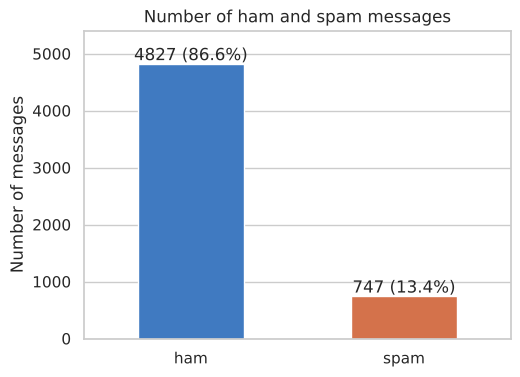

In [4]:
plt.figure(figsize=(5.5, 4))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=[ham_color, spam_color], legend=False, width=0.5)

# Write the count and the percentage on top of each bar
for i in range(len(counts)):
    ax.text(i, counts.values[i] + 60, str(counts.values[i]) + " (" + str(percentages.values[i]) + "%)", ha="center")

plt.title("Number of ham and spam messages")
plt.xlabel("")
plt.ylabel("Number of messages")
plt.ylim(0, counts.max() * 1.12)
plt.show()

**Observations**

- The dataset has 5,574 messages: 4,827 ham (86.6%) and 747 spam (13.4%).
- The classes are **imbalanced**: there are about 6 ham messages for every spam message. Because of this, accuracy alone is not enough to judge a model, and precision, recall and F1-score are also needed.

## 3. Data cleaning

In [5]:
print("Null values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Null values:
label      0
message    0
dtype: int64

Duplicate rows: 403


In [6]:
# Remove duplicate messages so that the same message cannot be in both the training and the test set
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print()
print(df["label"].value_counts())
print()
print((df["label"].value_counts(normalize=True) * 100).round(2))

Shape after removing duplicates: (5171, 2)

label
ham     4518
spam     653
Name: count, dtype: int64

label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


In [7]:
# Convert the label to a number: ham = 0, spam = 1
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
df.head()

,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


### Message length

In [8]:
# Number of characters in each message
df["length"] = df["message"].str.len()

df.groupby("label")["length"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4518.0,70.9,56.6,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.7,29.8,13.0,132.0,148.0,157.0,223.0


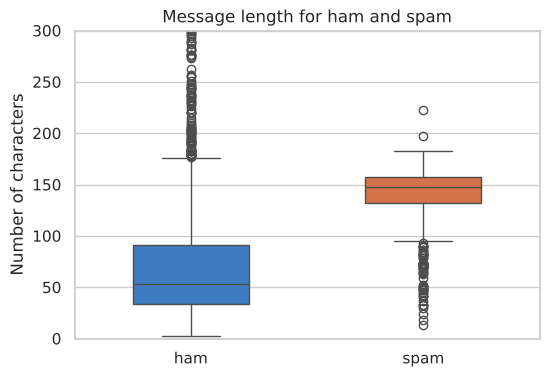

In [9]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="label", y="length", order=["ham", "spam"], hue="label", hue_order=["ham", "spam"],
            palette=[ham_color, spam_color], legend=False, width=0.5)
plt.title("Message length for ham and spam")
plt.xlabel("")
plt.ylabel("Number of characters")
plt.ylim(0, 300)       # a few very long ham messages are cut off so that the boxes are easy to see
plt.show()

**Observations**

- There are no null values.
- 403 duplicate messages were removed, leaving 5,171 messages: 4,518 ham (87.37%) and 653 spam (12.63%).
- Spam messages are longer than ham messages. The average spam message has about 138 characters and the average ham message about 71. Half of all spam messages are between 132 and 157 characters long.

## 4. Text preprocessing

Machine learning models cannot work with raw text, so each message is cleaned first:

1. **Lowercase conversion**: "FREE", "Free" and "free" become the same word.
2. **Punctuation removal**: characters like `! . , ?` are removed.
3. **Stopword removal**: very common words like "the", "is", "and" are removed because they appear in both spam and ham and carry little meaning.
4. **Stemming**: each word is cut down to its root, so "winning", "wins" and "win" all become "win".

In [10]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

print("Number of English stopwords:", len(stop_words))
print("Some stopwords:", sorted(stop_words)[:12])

Number of English stopwords: 198
Some stopwords: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any']


In [11]:
def preprocess(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Replace every punctuation character with a space
    for character in string.punctuation:
        text = text.replace(character, " ")

    # 3. Split into words and remove the stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # 4. Stemming
    words = [stemmer.stem(word) for word in words]

    return " ".join(words)


# Try the function on one message
example = "Congratulations!! You are the WINNER of a FREE ticket. Call now to claim your prize."
print("Before:", example)
print("After :", preprocess(example))

Before: Congratulations!! You are the WINNER of a FREE ticket. Call now to claim your prize.
After : congratul winner free ticket call claim prize


In [12]:
df["clean_message"] = df["message"].apply(preprocess)

pd.set_option("display.max_colwidth", 80)
df[["label", "message", "clean_message"]].head()

,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e bu...",go jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA ...,free entri 2 wkli comp win fa cup final tkt 21st may 2005 text fa 87121 rece...
3,ham,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,ham,"Nah I don't think he goes to usf, he lives around here though",nah think goe usf live around though


## 5. WordClouds (bonus)

A WordCloud shows the most frequent words in a larger size. One cloud is made from all the spam messages and one from all the ham messages.

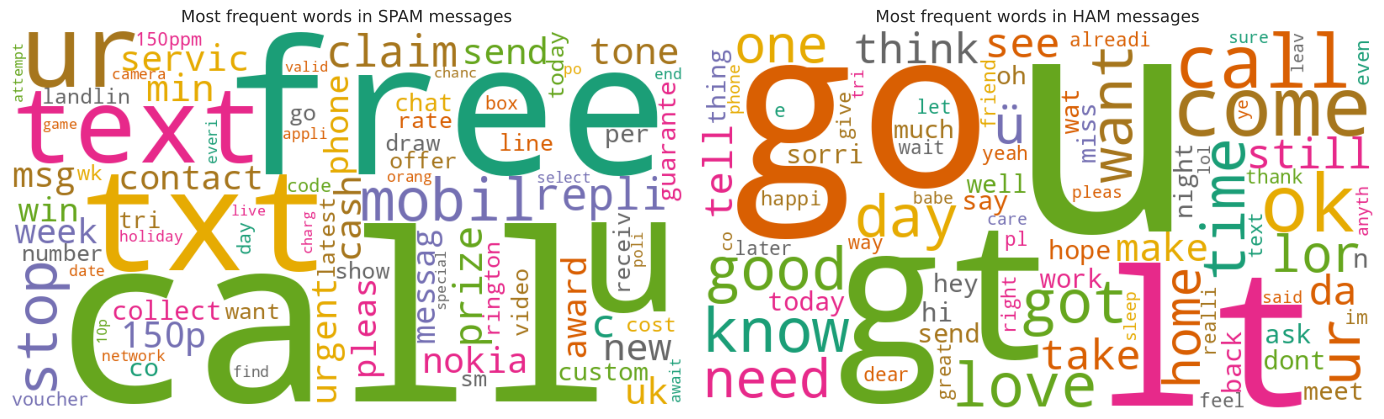

In [13]:
spam_text = " ".join(df[df["label"] == "spam"]["clean_message"])
ham_text = " ".join(df[df["label"] == "ham"]["clean_message"])

# collocations=False counts single words only; max_words=80 keeps the 80 most frequent words
spam_cloud = WordCloud(width=800, height=450, background_color="white", colormap="Dark2",
                       collocations=False, max_words=80, random_state=42).generate(spam_text)
ham_cloud = WordCloud(width=800, height=450, background_color="white", colormap="Dark2",
                      collocations=False, max_words=80, random_state=42).generate(ham_text)

plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
plt.imshow(spam_cloud)
plt.title("Most frequent words in SPAM messages")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ham_cloud)
plt.title("Most frequent words in HAM messages")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# The 10 most frequent words in each class
spam_top = pd.Series(spam_text.split()).value_counts().head(10)
ham_top = pd.Series(ham_text.split()).value_counts().head(10)

print("Top 10 spam words:", list(spam_top.index))
print("Top 10 ham words :", list(ham_top.index))

Top 10 spam words: ['call', 'free', '2', 'u', 'txt', 'text', 'ur', 'mobil', 'stop', '4']
Top 10 ham words : ['u', 'go', 'get', '2', 'gt', 'lt', 'come', 'ok', 'call', 'like']


**Observations**

- Spam messages are full of words like "call", "free", "txt", "text", "mobil", "claim" and "prize". They push the reader to act and promise a reward.
- Ham messages contain everyday words like "go", "get", "come", "ok" and "like".
- "u", "ur", "2" and "4" are texting short forms of "you", "your", "to" and "for". They appear in both classes.
- "gt" and "lt" in the ham cloud are not real words. They are leftovers of the HTML codes `&gt;` and `&lt;` in the original data.

## 6. Train / test split

80% of the messages are used for training and 20% for testing. `stratify=y` keeps the same percentage of spam in both parts.

The split is done **before** TF-IDF, so that the TF-IDF vocabulary is learned only from the training messages. This way no information from the test set leaks into training.

In [15]:
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training messages:", len(X_train))
print("Testing messages :", len(X_test))
print("Spam in the test set:", y_test.sum(), "| Ham in the test set:", (y_test == 0).sum())

Training messages: 4136
Testing messages : 1035
Spam in the test set: 131 | Ham in the test set: 904


## 7. Feature extraction with TF-IDF

**What does TF-IDF measure?**

TF-IDF stands for **Term Frequency - Inverse Document Frequency**. It gives every word in every message a score that shows how important that word is for that message.

- **TF (Term Frequency)**: how often the word appears in this message. More often means a higher score.
- **IDF (Inverse Document Frequency)**: how rare the word is across all the messages. A word that appears in almost every message (like "ok") gets a low score. A word that appears in only a few messages (like "prize") gets a high score.

**TF-IDF = TF × IDF**

So a word gets a high TF-IDF score when it appears often in one message but rarely in the other messages. Such words are the most useful for telling messages apart.

`TfidfVectorizer` turns every message into a row of numbers, with one column for each word in the vocabulary.

In [16]:
vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)    # learn the vocabulary from the training messages
X_test_tfidf = vectorizer.transform(X_test)          # use the same vocabulary for the test messages

print("Shape of the training matrix:", X_train_tfidf.shape)
print("Shape of the testing matrix :", X_test_tfidf.shape)
print("Number of words in the vocabulary:", len(vectorizer.get_feature_names_out()))

Shape of the training matrix: (4136, 6418)
Shape of the testing matrix : (1035, 6418)
Number of words in the vocabulary: 6418


## 8. Train the classifiers

Two classifiers are trained on the TF-IDF features:

- **Multinomial Naive Bayes**: uses the probability of each word appearing in spam and in ham. It is the standard model for text classification.
- **Support Vector Machine (LinearSVC)**: finds the boundary that separates spam from ham with the widest possible gap.

In [17]:
models = {
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(),
}

for name in models:
    models[name].fit(X_train_tfidf, y_train)
    print(name, "trained")

Naive Bayes trained
SVM trained


## 9. Evaluate the classifiers

Spam is the "positive" class (1) and ham is the "negative" class (0).

- **Accuracy**: percentage of all messages classified correctly.
- **Precision**: of the messages the model marked as spam, how many really were spam.
- **Recall**: of the messages that really were spam, how many the model caught.
- **F1-score**: a single number that combines precision and recall.
- **Confusion matrix**: rows are the actual class, columns are the predicted class.

In [18]:
rows = []
predictions = {}

for name in models:
    y_pred = models[name].predict(X_test_tfidf)
    predictions[name] = y_pred

    rows.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
    ])

    print("=" * 55)
    print(name)
    print("=" * 55)
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    print()
    print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))

Naive Bayes
Confusion matrix:
[[903   1]
 [ 37  94]]

              precision    recall  f1-score   support

         ham     0.9606    0.9989    0.9794       904
        spam     0.9895    0.7176    0.8319       131

    accuracy                         0.9633      1035
   macro avg     0.9751    0.8582    0.9056      1035
weighted avg     0.9643    0.9633    0.9607      1035

SVM
Confusion matrix:
[[901   3]
 [ 16 115]]

              precision    recall  f1-score   support

         ham     0.9826    0.9967    0.9896       904
        spam     0.9746    0.8779    0.9237       131

    accuracy                         0.9816      1035
   macro avg     0.9786    0.9373    0.9566      1035
weighted avg     0.9815    0.9816    0.9812      1035



In [19]:
results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"])
results = results.sort_values("F1-score", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,SVM,0.9816,0.9746,0.8779,0.9237
1,Naive Bayes,0.9633,0.9895,0.7176,0.8319


### Confusion matrices as heatmaps

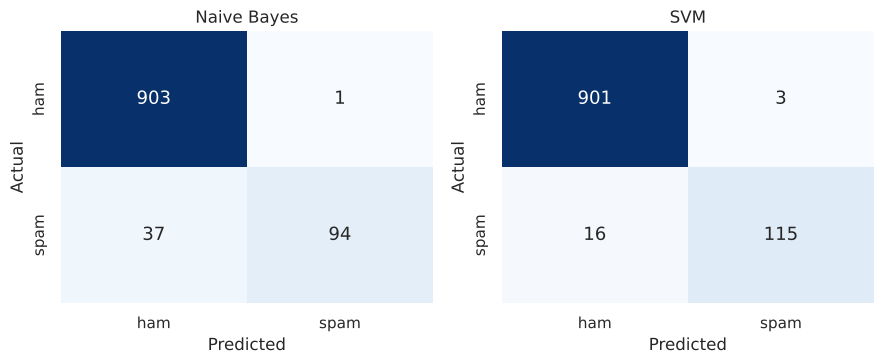

In [20]:
plt.figure(figsize=(9, 3.8))
i = 1
for name in models:
    cm = confusion_matrix(y_test, predictions[name])
    plt.subplot(1, 2, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], annot_kws={"size": 13})
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    i = i + 1
plt.tight_layout()
plt.show()

### Comparing the models

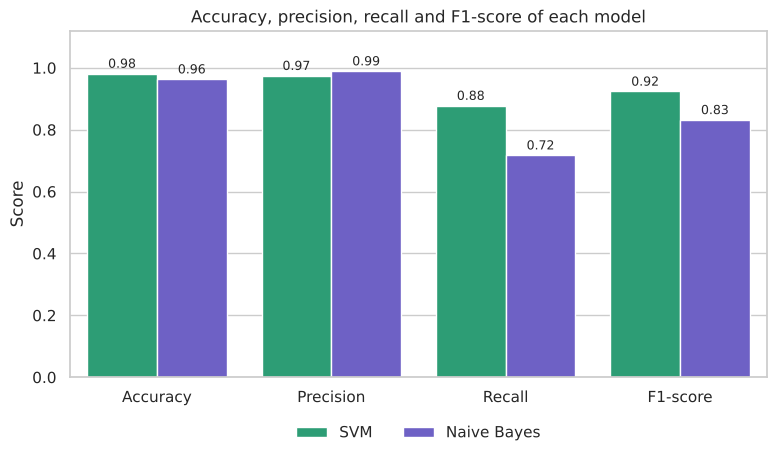

In [21]:
# Reshape the table so that the four metrics can be drawn side by side
results_long = results.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(9, 4.5))
# Green and purple are used for the models, because blue and orange already mean ham and spam
ax = sns.barplot(data=results_long, x="Metric", y="Score", hue="Model", palette=["#1baf7a", "#6250d6"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9)
plt.ylim(0, 1.12)
plt.xlabel("")
plt.title("Accuracy, precision, recall and F1-score of each model")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.show()

In [22]:
# How many spam messages did each model miss, and how many ham messages did it wrongly mark as spam?
for name in models:
    cm = confusion_matrix(y_test, predictions[name])
    print(name, ": missed spam =", cm[1, 0], "of", cm[1].sum(), "| ham marked as spam =", cm[0, 1], "of", cm[0].sum())

Naive Bayes : missed spam = 37 of 131 | ham marked as spam = 1 of 904
SVM : missed spam = 16 of 131 | ham marked as spam = 3 of 904


In [23]:
# Accuracy of a "model" that simply says ham for every message
print("Accuracy of always predicting ham:", round((y_test == 0).mean(), 4))

Accuracy of always predicting ham: 0.8734


## 10. Why recall is important for spam detection

**Recall answers the question: of all the real spam messages, how many did the model catch?**

- **A spam filter exists to catch spam.** Recall measures exactly that. A model with low recall lets a lot of spam through to the inbox.
- **Missed spam can be harmful.** Spam often contains scams, fake prize offers and phishing links. Every spam message that is missed is a chance for the user to be cheated.
- **Accuracy hides the problem.** About 87% of the messages are ham, so a model that says "ham" for every message would already have an accuracy of 87.34%, while catching no spam at all (recall of 0). In the results above, Naive Bayes has an accuracy of 96.33%, which looks very good, but it misses 37 of the 131 spam messages (recall of 71.76%).

**Recall is not the only thing that matters.** If a model marks a ham message as spam, the user may miss an important message. That is measured by precision. A good spam filter needs high recall while keeping precision high, and the F1-score combines both into one number.

## 11. Best model

In [24]:
# The first row of the results table has the highest F1-score
best_name = results.loc[0, "Model"]
best_model = models[best_name]

print("Best-performing model:", best_name)
print("Accuracy :", round(results.loc[0, "Accuracy"], 4))
print("Precision:", round(results.loc[0, "Precision"], 4))
print("Recall   :", round(results.loc[0, "Recall"], 4))
print("F1-score :", round(results.loc[0, "F1-score"], 4))

Best-performing model: SVM
Accuracy : 0.9816
Precision: 0.9746
Recall   : 0.8779
F1-score : 0.9237


### Best model: Support Vector Machine (LinearSVC)

**Justification**

1. **Highest recall (87.79%).** It caught 115 of the 131 spam messages in the test set. Naive Bayes caught 94 (71.76%).
2. **Highest F1-score (0.9237) and highest accuracy (98.16%).**
3. **Precision is still high (97.46%).** Only 3 of the 904 ham messages were wrongly marked as spam.

**What about Naive Bayes?** It has the highest precision (98.95%): only 1 ham message was wrongly marked as spam. But it misses more than one in four spam messages. A likely reason is the class imbalance: only about 13% of the training messages are spam, so the model leans towards predicting ham.

**Limitations**

- The best model still misses 16 of the 131 spam messages.
- The dataset contains SMS messages, not emails. A filter for real email would have to be trained on email data.

### Testing the best model on new messages

In [25]:
new_messages = [
    "Congratulations! You have won a free prize of 1000 pounds. Call now to claim.",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT! Your mobile number has been selected for a cash reward. Reply WIN to claim.",
    "Can you send me the notes from today's class?",
]

# The new messages must go through the same preprocessing and the same TF-IDF vectorizer
new_clean = [preprocess(message) for message in new_messages]
new_tfidf = vectorizer.transform(new_clean)
new_predictions = best_model.predict(new_tfidf)

for message, prediction in zip(new_messages, new_predictions):
    label = "SPAM" if prediction == 1 else "HAM"
    print(label, "->", message)

SPAM -> Congratulations! You have won a free prize of 1000 pounds. Call now to claim.
HAM -> Hey, are we still meeting for lunch tomorrow?
SPAM -> URGENT! Your mobile number has been selected for a cash reward. Reply WIN to claim.
HAM -> Can you send me the notes from today's class?


## 12. Conclusion

- The SMS Spam Collection dataset has 5,574 messages, of which 13.4% are spam. After removing duplicates, 5,171 messages were used.
- Each message was converted to lowercase, punctuation and stopwords were removed, and the words were stemmed.
- The cleaned text was converted into numbers with TF-IDF, which gives a high score to words that are frequent in one message but rare in the others.
- Two classifiers were trained: Multinomial Naive Bayes and a Support Vector Machine.
- **The Support Vector Machine is the best-performing model**, with 98.16% accuracy, 97.46% precision, 87.79% recall and an F1-score of 0.9237.
- Recall is important because every spam message that is missed reaches the user, and accuracy alone is misleading on an imbalanced dataset.

**Future improvements:** try more classifiers, and train the model on real email data.